# Soal 12 — FIS untuk Interpretasi Risiko Ketidakstabilan Grid (Mamdani)

**Nama:** Marsa Naufal  **NIM:** 04231047  **Seed:** 47 (dua digit terakhir NIM)
**Dataset:** D6 — Electrical Grid Stability Simulated Data, UCI (10.000 simulasi grid 4 node)
**Library:** `scikit-fuzzy` (Mamdani FIS), `pandas`/`numpy`/`scipy`/`scikit-learn`.

Alur: *Business Understanding → Data Understanding → Data Preparation → Modeling → Evaluation → Interpretasi Hasil*. Jawaban butir (a)–(d) ditandai **Jawaban 12a–12d**.

## 1. Business Understanding

**Latar belakang.** Dataset ini berasal dari konsep *Decentral Smart Grid Control*: satu pembangkit (node 1) dan tiga konsumen (node 2–4) yang mengatur pemakaian listrik berdasarkan harga. Grid bisa menjadi **tidak stabil** (frekuensi berosilasi dan membesar) kalau peserta bereaksi terlalu lambat atau terlalu agresif terhadap perubahan harga. Operator grid butuh **indikator risiko yang bisa dijelaskan**, bukan sekadar "model bilang tidak stabil". Fuzzy logic cocok karena aturannya ditulis dalam bahasa manusia, misalnya *"jika waktu reaksi lambat dan … maka risiko tinggi"*. Ibaratnya lampu indikator di dasbor mobil yang disertai buku manual, bukan kotak hitam.

**Rumusan masalah.**
1. Tiga fitur mana yang paling informatif terhadap stabilitas, berdasarkan statistik data latih?
2. Bisakah Mamdani FIS dengan membership dari distribusi data latih menghasilkan skor *Instability Risk* 0–100 yang memisahkan grid stabil dan tidak stabil?
3. Seberapa jauh FIS lebih baik daripada aturan threshold sederhana, dan apa yang dikorbankan dibanding model *black-box*?

**Tujuan.** Membangun Mamdani FIS 3 input dengan rule base yang lengkap (tanpa celah), memilih threshold dari validation set saja, lalu menilai performa dan interpretabilitasnya di test set.

**Kriteria kesuksesan.**

| Kriteria | Ambang |
|---|---|
| Rule base lengkap | 0 kombinasi antecedent tanpa rule dan 0 sampel dengan aktivasi maksimum < 0.2 |
| FIS lebih baik dari baseline threshold satu fitur | macro-F1 test FIS > baseline |
| Kemampuan ranking skor risiko | ROC-AUC test ≥ 0.70 |

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import skfuzzy as fuzz
from skfuzzy import control as ctrl
from itertools import product
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import mutual_info_classif
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (f1_score, confusion_matrix, classification_report, roc_auc_score,
                             accuracy_score, balanced_accuracy_score)

SEED = 47
np.random.seed(SEED)
pd.set_option("display.width", 160)
plt.rcParams["figure.dpi"] = 110

## 2. Data Understanding

### 2.1 Memuat data dan sampel

In [2]:
df = pd.read_csv("data/Data_for_UCI_named.csv")
print("Ukuran data:", df.shape)
df.head(20)

Ukuran data: (10000, 14)


,tau1,tau2,tau3,tau4,p1,p2,p3,p4,g1,g2,g3,g4,stab,stabf
0,2.959060,3.079885,8.381025,9.780754,3.763085,-0.782604,-1.257395,-1.723086,0.650456,0.859578,0.887445,0.958034,0.055347,unstable
1,9.304097,4.902524,3.047541,1.369357,5.067812,-1.940058,-1.872742,-1.255012,0.413441,0.862414,0.562139,0.781760,-0.005957,stable
2,8.971707,8.848428,3.046479,1.214518,3.405158,-1.207456,-1.277210,-0.920492,0.163041,0.766689,0.839444,0.109853,0.003471,unstable
3,0.716415,7.669600,4.486641,2.340563,3.963791,-1.027473,-1.938944,-0.997374,0.446209,0.976744,0.929381,0.362718,0.028871,unstable
4,3.134112,7.608772,4.943759,9.857573,3.525811,-1.125531,-1.845975,-0.554305,0.797110,0.455450,0.656947,0.820923,0.049860,unstable
5,6.999209,9.109247,3.784066,4.267788,4.429669,-1.857139,-0.670397,-1.902133,0.261793,0.077930,0.542884,0.469931,-0.017385,stable
6,6.710166,3.765204,6.929314,8.818562,2.397419,-0.614590,-1.208826,-0.574004,0.177890,0.397977,0.402046,0.376630,0.005954,unstable
7,6.953512,1.379125,5.719400,7.870307,3.224495,-0.748998,-1.186517,-1.288980,0.371385,0.633204,0.732741,0.380544,0.016634,unstable
8,4.689852,4.007747,1.478573,3.733787,4.041300,-1.410344,-1.238204,-1.392751,0.269708,0.250364,0.164941,0.482439,-0.038677,stable
9,9.841496,1.413822,9.769856,7.641616,4.727595,-1.991363,-0.857637,-1.878594,0.376356,0.544415,0.792039,0.116263,0.012383,unstable


### 2.2 Atribut dan tipe data

| Kolom | Arti | Rentang / tipe |
|---|---|---|
| tau1–tau4 | waktu reaksi peserta (node 1 = pembangkit, 2–4 = konsumen) terhadap perubahan harga, dalam detik | numerik, 0.5–10 |
| p1–p4 | daya nominal: p1 diproduksi (positif), p2–p4 dikonsumsi (negatif) | numerik |
| g1–g4 | koefisien elastisitas harga: seberapa agresif peserta mengubah daya saat harga berubah | numerik, 0.05–1 |
| stab | bagian real terbesar dari akar persamaan karakteristik sistem; **positif = tidak stabil** | numerik |
| stabf | label `stable` / `unstable` (target) | kategorikal |

In [3]:
df.info()
display(df.describe().T.round(3))
print("Missing value total :", df.isna().sum().sum())
print("Baris duplikat      :", df.duplicated().sum())
print("Komposisi target    :", df["stabf"].value_counts().to_dict())
print("Cek keseimbangan daya: max |p1+p2+p3+p4| =", (df[["p1", "p2", "p3", "p4"]].sum(axis=1)).abs().max())
print("Cek konsistensi label: stabf == (stab>0 ? unstable : stable) ->",
      (df["stabf"] == np.where(df["stab"] > 0, "unstable", "stable")).all())

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   tau1    10000 non-null  float64
 1   tau2    10000 non-null  float64
 2   tau3    10000 non-null  float64
 3   tau4    10000 non-null  float64
 4   p1      10000 non-null  float64
 5   p2      10000 non-null  float64
 6   p3      10000 non-null  float64
 7   p4      10000 non-null  float64
 8   g1      10000 non-null  float64
 9   g2      10000 non-null  float64
 10  g3      10000 non-null  float64
 11  g4      10000 non-null  float64
 12  stab    10000 non-null  float64
 13  stabf   10000 non-null  str    
dtypes: float64(13), str(1)
memory usage: 1.1 MB


,count,mean,std,min,25%,50%,75%,max
tau1,10000.0,5.250,2.743,0.501,2.875,5.250,7.625,9.999
tau2,10000.0,5.250,2.743,0.500,2.875,5.250,7.625,10.000
tau3,10000.0,5.250,2.743,0.501,2.876,5.250,7.625,9.999
tau4,10000.0,5.250,2.743,0.500,2.875,5.250,7.625,9.999
p1,10000.0,3.750,0.752,1.583,3.218,3.751,4.282,5.864
p2,10000.0,-1.250,0.433,-2.000,-1.625,-1.250,-0.875,-0.500
p3,10000.0,-1.250,0.433,-2.000,-1.625,-1.250,-0.875,-0.500
p4,10000.0,-1.250,0.433,-2.000,-1.625,-1.250,-0.875,-0.500
g1,10000.0,0.525,0.274,0.050,0.288,0.525,0.762,1.000
g2,10000.0,0.525,0.274,0.050,0.288,0.525,0.762,1.000


Missing value total : 0
Baris duplikat      : 0
Komposisi target    : {'unstable': 6380, 'stable': 3620}
Cek keseimbangan daya: max |p1+p2+p3+p4| = 5.773159728050814e-15
Cek konsistensi label: stabf == (stab>0 ? unstable : stable) -> True


In [4]:
FEAT_ALL = [f"{p}{i}" for p in ["tau", "p", "g"] for i in range(1, 5)]
q1, q3 = df[FEAT_ALL].quantile(.25), df[FEAT_ALL].quantile(.75); iqr = q3 - q1
print("Outlier 1.5×IQR per fitur:\n", ((df[FEAT_ALL] < q1 - 1.5 * iqr) | (df[FEAT_ALL] > q3 + 1.5 * iqr)).sum().to_string())

Outlier 1.5×IQR per fitur:
 tau1    0
tau2    0
tau3    0
tau4    0
p1      1
p2      0
p3      0
p4      0
g1      0
g2      0
g3      0
g4      0


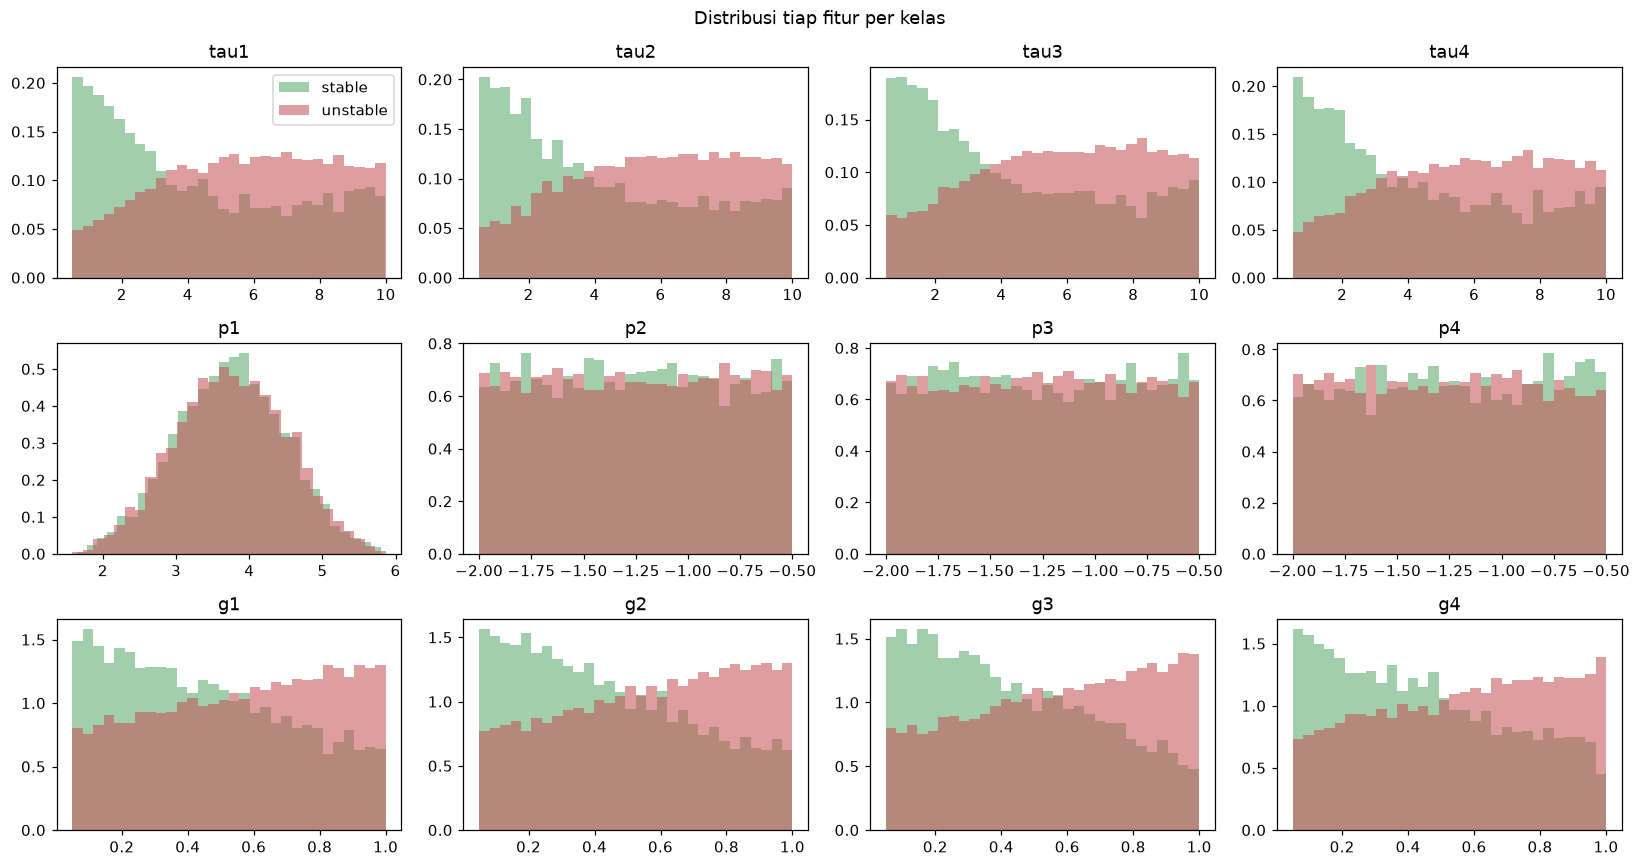

In [5]:
fig, axes = plt.subplots(3, 4, figsize=(15, 8))
for ax, c in zip(axes.flat, FEAT_ALL):
    ax.hist(df.loc[df.stabf == "stable", c], bins=30, alpha=.55, density=True, label="stable", color="#55A868")
    ax.hist(df.loc[df.stabf == "unstable", c], bins=30, alpha=.55, density=True, label="unstable", color="#C44E52")
    ax.set_title(c)
axes[0, 0].legend(); plt.suptitle("Distribusi tiap fitur per kelas"); plt.tight_layout(); plt.show()

**Interpretasi Data Understanding.**
- Ada **10.000 baris dan 14 kolom**, tanpa missing value, duplikat, maupun outlier. Semua fitur menyebar **seragam (uniform)** karena memang dibangkitkan acak oleh simulator.
- Target **tidak seimbang**: 6.380 unstable (63.8%) vs 3.620 stable. Accuracy saja bisa menipu, karena menebak "unstable" terus sudah memberi accuracy 64%.
- **p1 = −(p2 + p3 + p4)** secara persis (selisih ≈ 10⁻¹⁵): daya yang diproduksi sama dengan total daya yang dikonsumsi. Jadi p1 tidak membawa informasi baru.
- `stabf` 100% konsisten dengan tanda `stab`, sehingga `stab` **wajib dibuang** dari input (bocoran label).
- Dari histogram, distribusi **tau** dan **g** bergeser antara kelas: grid unstable cenderung punya τ dan g lebih besar. Sebaliknya, **p1–p4 hampir identik** di kedua kelas. Namun pergeserannya kecil, dan tidak ada satu fitur pun yang memisahkan kelas dengan tegas. Ini sinyal awal bahwa model 3 fitur akan punya batas performa.

## 3. Data Preparation

1. **Kolom `stab` dibuang.** Label `stabf` hanyalah tanda dari `stab` (positif = unstable). Kalau `stab` dipakai sebagai input, itu sama dengan "menyontek kunci jawaban" (*target leakage*).
2. **Tidak ada missing value, duplikat, atau outlier** yang perlu ditangani. Data hasil simulasi dengan sebaran seragam (uniform), jadi tidak ada baris yang dibuang.
3. **Label:** unstable = 1 (kelas positif, yang ingin dideteksi), stable = 0.
4. **Split 60/20/20 berstrata (seed 47):**
   - *Train*: memilih fitur, membuat membership function, dan mengecek rule.
   - *Validation*: hanya untuk memilih threshold.
   - *Test*: evaluasi akhir sekali.
5. **Tidak ada scaling**, karena FIS membaca nilai asli lewat membership function yang dibangun dari kuartil data latih. Ketidakseimbangan kelas (64% unstable) ditangani lewat pemilihan threshold yang memaksimalkan **macro-F1**, bukan accuracy.

In [6]:
y_all = (df["stabf"] == "unstable").astype(int).values
X_all = df[FEAT_ALL]
X_tmp, X_te, y_tmp, y_te = train_test_split(X_all, y_all, test_size=0.2, stratify=y_all, random_state=SEED)
X_tr, X_va, y_tr, y_va = train_test_split(X_tmp, y_tmp, test_size=0.25, stratify=y_tmp, random_state=SEED)
print(f"train={len(X_tr)}, val={len(X_va)}, test={len(X_te)} | porsi unstable train={y_tr.mean():.3f}")

train=6000, val=2000, test=2000 | porsi unstable train=0.638


## 4. Modeling — Mamdani FIS

### Jawaban 12a — Pemilihan tiga fitur, universe, dan membership function

**Analisis statistik (hanya data latih).** Setiap fitur dinilai dengan tiga ukuran yang saling melengkapi:
- **Korelasi point-biserial |r|**: seberapa kuat hubungan linear dengan label.
- **Mutual information (MI)**: menangkap hubungan apa pun, termasuk yang tidak linear.
- **AUC satu fitur**: kalau hanya fitur ini yang dipakai untuk mengurutkan sampel, seberapa sering sampel unstable berada di atas yang stable (0.5 = acak).

Ketiga ukuran diubah menjadi peringkat lalu dirata-rata, supaya pilihan tidak bergantung pada satu ukuran saja.

In [7]:
mi = mutual_info_classif(X_tr, y_tr, random_state=SEED)
rows = []
for c, m in zip(FEAT_ALL, mi):
    a, b = X_tr.loc[y_tr == 1, c], X_tr.loc[y_tr == 0, c]
    u, p = stats.mannwhitneyu(a, b)
    rows.append({"fitur": c, "r": np.corrcoef(X_tr[c], y_tr)[0, 1], "MI": m,
                 "AUC": max(u / (len(a) * len(b)), 1 - u / (len(a) * len(b))), "p_MannWhitney": p})
rank = pd.DataFrame(rows).set_index("fitur")
rank["|r|"] = rank["r"].abs()
rank["rata2_peringkat"] = rank[["|r|", "MI", "AUC"]].rank(ascending=False).mean(axis=1)
rank = rank.sort_values("rata2_peringkat")
FEATS = rank.index[:3].tolist()
print("Tiga fitur terpilih:", FEATS)
rank.round(4).assign(p_MannWhitney=rank["p_MannWhitney"].map("{:.1e}".format))

Tiga fitur terpilih: ['tau1', 'tau4', 'tau2']


,r,MI,AUC,p_MannWhitney,|r|,rata2_peringkat
fitur,,,,,,
tau1,0.2442,0.0406,0.6470,4.1e-80,0.2442,1.0000
tau4,0.2431,0.0398,0.6467,8.8e-80,0.2431,2.0000
tau2,0.2399,0.0347,0.6441,4.4e-77,0.2399,3.3333
g2,0.2360,0.0297,0.6418,1.2e-74,0.2360,4.3333
tau3,0.2266,0.0347,0.6359,9.6e-69,0.2266,5.0000
g3,0.2277,0.0223,0.6368,1.3e-69,0.2277,5.3333
g1,0.2156,0.0193,0.6295,1.3e-62,0.2156,7.0000
g4,0.1973,0.0138,0.6185,1.0e-52,0.1973,8.0000
p4,-0.0323,0.0020,0.5194,1.3e-02,0.0323,9.0000


**Universe dan membership.** Untuk tiap fitur terpilih:
- **Universe** = [min, max] data latih.
- **Low** = trapesium [min, min, Q1, Q2], **Medium** = segitiga [Q1, Q2, Q3], **High** = trapesium [Q2, Q3, max, max].
- Q1, Q2, Q3 adalah kuartil 25%, 50%, 75% data latih.

Kenapa memakai kuartil?
- Batas mengikuti sebaran data asli: "Low" artinya kira-kira seperempat data terbawah.
- Di setiap titik, jumlah derajat keanggotaan Low + Medium + High = 1 (*fuzzy partition*), jadi tidak ada nilai input yang "tidak dikenali".
- Trapesium di ujung membuat nilai ekstrem tetap 100% Low atau High.

**Output *Instability Risk* 0–100:** Low = trapesium [0, 0, 20, 45], Medium = segitiga [25, 50, 75], High = trapesium [55, 80, 100, 100]. Alasannya:
- Ketiga himpunan dibagi rata di skala 0–100 dan saling tumpang tindih sekitar 20 poin, supaya perpindahan risiko halus, tidak melompat.
- Ujungnya berbentuk trapesium agar risiko "pasti rendah" dan "pasti tinggi" punya area yang jelas.
- Bentuk output sengaja **tidak** diatur dari data, karena *Instability Risk* adalah skala buatan kita sendiri, bukan besaran fisik yang punya distribusi.

In [8]:
mf_par = {}
for f in FEATS:
    v = X_tr[f]
    lo, q1_, q2_, q3_, hi = v.min(), v.quantile(.25), v.quantile(.50), v.quantile(.75), v.max()
    mf_par[f] = {"Low": [lo, lo, q1_, q2_], "Medium": [q1_, q2_, q3_], "High": [q2_, q3_, hi, hi]}
pd.DataFrame({f: {k: np.round(v, 3).tolist() for k, v in d.items()} for f, d in mf_par.items()}).T

,Low,Medium,High
tau1,"[0.501, 0.501, 2.867, 5.214]","[2.867, 5.214, 7.671]","[5.214, 7.671, 9.998, 9.998]"
tau4,"[0.5, 0.5, 2.835, 5.194]","[2.835, 5.194, 7.566]","[5.194, 7.566, 9.999, 9.999]"
tau2,"[0.502, 0.502, 2.926, 5.243]","[2.926, 5.243, 7.59]","[5.243, 7.59, 9.998, 9.998]"


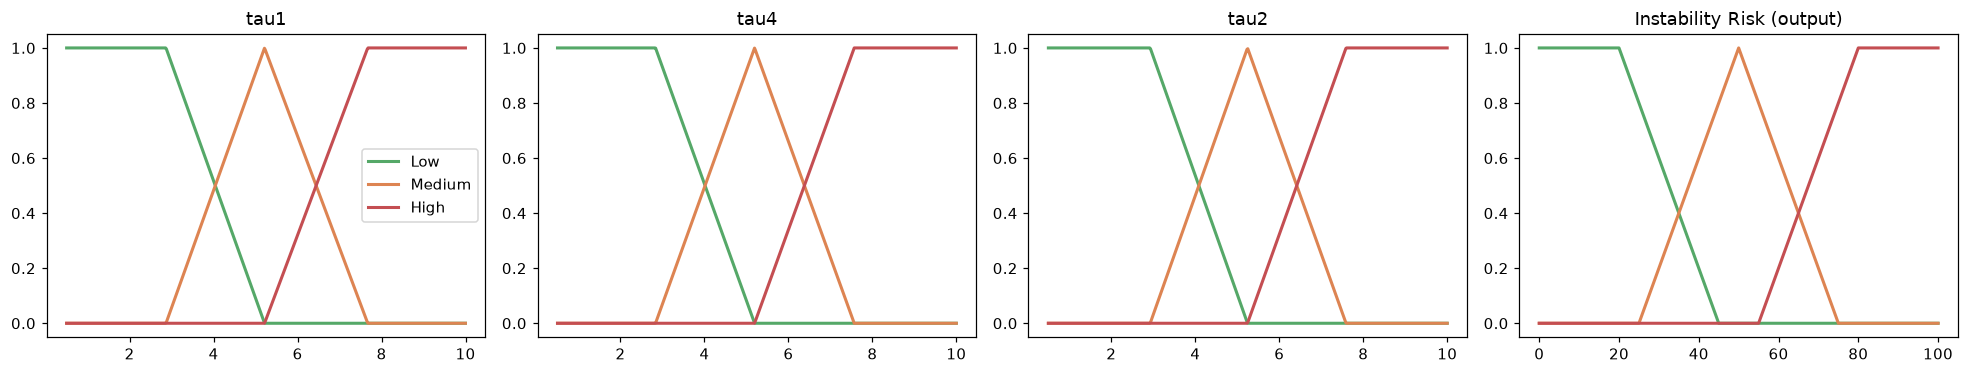

In [9]:
antecedents = {}
for f in FEATS:
    lo, hi = mf_par[f]["Low"][0], mf_par[f]["High"][3]
    a = ctrl.Antecedent(np.linspace(lo, hi, 501), f)
    a["Low"] = fuzz.trapmf(a.universe, mf_par[f]["Low"])
    a["Medium"] = fuzz.trimf(a.universe, mf_par[f]["Medium"])
    a["High"] = fuzz.trapmf(a.universe, mf_par[f]["High"])
    antecedents[f] = a
risk = ctrl.Consequent(np.linspace(0, 100, 501), "risk")   # defuzzifikasi default = centroid
risk["Low"] = fuzz.trapmf(risk.universe, [0, 0, 20, 45])
risk["Medium"] = fuzz.trimf(risk.universe, [25, 50, 75])
risk["High"] = fuzz.trapmf(risk.universe, [55, 80, 100, 100])

fig, axes = plt.subplots(1, 4, figsize=(18, 3.5))
for ax, var in zip(axes, list(antecedents.values()) + [risk]):
    for term, col in zip(["Low", "Medium", "High"], ["#55A868", "#DD8452", "#C44E52"]):
        ax.plot(var.universe, var[term].mf, lw=2, label=term, color=col)
    ax.set_title(var.label if var.label != "risk" else "Instability Risk (output)"); ax.set_ylim(-.05, 1.05)
axes[0].legend(); plt.tight_layout(); plt.show()

### Jawaban 12b — Rule base, coverage, dan deteksi *rule gaps*

**Arah pengaruh fitur.** Ketiga fitur terpilih berkorelasi **positif** dengan unstable. Secara fisika, waktu reaksi (τ) yang lebih lama berarti peserta terlambat merespons perubahan harga. Ibaratnya sopir yang telat menginjak rem: koreksinya datang ketika keadaan sudah berubah, sehingga osilasi justru diperkuat.

**Coverage.** Agar **seluruh kombinasi tercakup**, dibuat rule untuk semua 3 × 3 × 3 = **27 kombinasi** Low/Medium/High (≥ 9 rule sesuai soal). Konsekuen disusun dalam dua langkah:

- **Rule versi 1 (hipotesis awal, gaya pakar).** Setiap input diberi "poin bahaya" Low = 0, Medium = 1, High = 2. Poin dijumlahkan (0–6): 0–2 → risiko **Low**, 3 → **Medium**, 4–6 → **High**. Asumsinya, makin besar τ makin berbahaya, secara lurus (linear).
- Konsekuen versi 1 lalu **dicek terhadap data latih**: setiap sampel latih dimasukkan ke kombinasi dengan derajat keanggotaan terbesar, lalu dihitung porsi unstable di kombinasi itu. Rule yang konsekuennya bertentangan dengan porsi ini adalah rule yang "tidak didukung data".

**Deteksi rule gaps** dilakukan dengan dua cara:
1. **Struktural:** cek apakah setiap kombinasi antecedent (27) punya minimal satu rule.
2. **Empiris:** untuk setiap sampel latih, hitung **aktivasi rule terkuat** (firing strength = min derajat keanggotaan antecedent, operator AND). Kalau aktivasi maksimumnya kecil (< 0.2), berarti tidak ada rule yang "merasa bertanggung jawab" atas sampel itu, dan itulah celah.

Supaya detektornya terbukti bekerja, dibuat juga simulasi: sebagian rule sengaja dihapus, lalu dilihat apakah celahnya terdeteksi.

In [10]:
TERMS = ["Low", "Medium", "High"]
POIN = {"Low": 0, "Medium": 1, "High": 2}

def konsekuen_v1(combo):
    s = sum(POIN[t] for t in combo)
    return "Low" if s <= 2 else ("Medium" if s == 3 else "High")

combos = list(product(TERMS, repeat=3))
rule_table = pd.DataFrame([{**dict(zip(FEATS, c)), "risk_v1": konsekuen_v1(c)} for c in combos])

def memberships(X):
    """Derajat keanggotaan tiap sampel: dict[(fitur, term)] -> array."""
    return {(f, t): fuzz.interp_membership(antecedents[f].universe, antecedents[f][t].mf, X[f].values)
            for f in FEATS for t in TERMS}

def firing(X, table):
    m = memberships(X)
    return np.column_stack([np.minimum.reduce([m[(f, r[f])] for f in FEATS]) for _, r in table.iterrows()])

fire_tr = firing(X_tr, rule_table)
dom = fire_tr.argmax(1)
rule_table["n_sampel_train"] = np.bincount(dom, minlength=27)
rule_table["porsi_unstable_train"] = [y_tr[dom == i].mean() for i in range(27)]
print("Porsi unstable data latih menurut konsekuen rule versi 1:")
rule_table.groupby("risk_v1")["porsi_unstable_train"].agg(["mean", "min", "max", "count"]).round(3)

Porsi unstable data latih menurut konsekuen rule versi 1:


,mean,min,max,count
risk_v1,,,,
High,0.847,0.717,0.935,10
Low,0.471,0.217,0.685,10
Medium,0.680,0.602,0.934,7


Rentang porsi unstable antar-konsekuen ternyata **saling tumpang tindih**: ada rule "Medium" dengan porsi unstable lebih tinggi dari sebagian rule "High", dan ada rule "Low" yang porsi unstable-nya di atas rata-rata data. Ada yang tidak beres dengan asumsi "makin besar τ makin berbahaya secara lurus". Ini dicek langsung dengan melihat porsi unstable per **desil** tiap fitur di data latih.

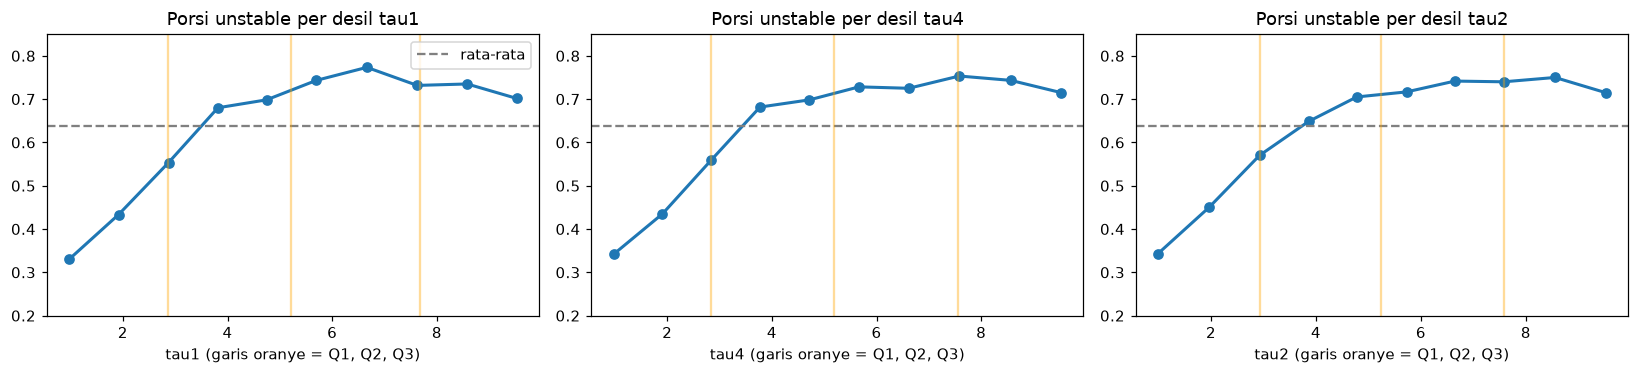

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, f in zip(axes, FEATS):
    rate = pd.Series(y_tr).groupby(pd.qcut(X_tr[f].values, 10)).mean()
    ax.plot([iv.mid for iv in rate.index], rate.values, "o-", lw=2)
    ax.axhline(y_tr.mean(), ls="--", c="gray", label="rata-rata")
    for q in [mf_par[f]["Medium"][0], mf_par[f]["Medium"][1], mf_par[f]["Medium"][2]]:
        ax.axvline(q, c="orange", alpha=.4)
    ax.set_title(f"Porsi unstable per desil {f}"); ax.set_xlabel(f"{f} (garis oranye = Q1, Q2, Q3)"); ax.set_ylim(0.2, 0.85)
axes[0].legend(); plt.tight_layout(); plt.show()

**Temuan penting.** Pengaruh τ **tidak lurus, melainkan jenuh**. Porsi unstable naik tajam dari ~0.33 (τ sangat kecil) sampai ~0.70 di sekitar median, lalu **mendatar** (bahkan sedikit turun) untuk τ besar. Jadi bagi stabilitas, τ "Medium" sudah sama berbahayanya dengan τ "High". Yang benar-benar menentukan adalah **ada tidaknya peserta yang bereaksi cepat (τ Low)**. Ibaratnya rem mobil: rem yang lambat setengah detik dan dua detik sama-sama sudah terlambat, sedangkan yang menolong hanya rem yang responsnya cepat.

**Rule versi 2 (revisi berbasis data latih):** konsekuen ditentukan oleh **jumlah input yang Low**:
- 0 input Low (semua peserta lambat) → **High**
- 1 input Low → **Medium**
- 2–3 input Low → **Low**

Rule ini tetap 27 (coverage lengkap), tetap mudah dibaca manusia, dan selaras dengan pola data. Versi mana yang dipakai diputuskan oleh **macro-F1 validation**, bukan test.

In [12]:
def konsekuen_v2(combo):
    n_low = sum(t == "Low" for t in combo)
    return "High" if n_low == 0 else ("Medium" if n_low == 1 else "Low")

rule_table["risk_v2"] = [konsekuen_v2(c) for c in combos]
display(rule_table.round(3))
print("Porsi unstable data latih menurut konsekuen rule versi 2:")
rule_table.groupby("risk_v2")["porsi_unstable_train"].agg(["mean", "min", "max", "count"]).round(3)

,tau1,tau4,tau2,risk_v1,n_sampel_train,porsi_unstable_train,risk_v2
0,Low,Low,Low,Low,314,0.217,Low
1,Low,Low,Medium,Low,207,0.459,Low
2,Low,Low,High,Low,309,0.327,Low
3,Low,Medium,Low,Low,220,0.473,Low
4,Low,Medium,Medium,Low,150,0.647,Medium
5,Low,Medium,High,Medium,209,0.646,Medium
6,Low,High,Low,Low,312,0.404,Low
7,Low,High,Medium,Medium,217,0.613,Medium
8,Low,High,High,High,307,0.733,Medium
9,Medium,Low,Low,Low,217,0.452,Low


Porsi unstable data latih menurut konsekuen rule versi 2:


,mean,min,max,count
risk_v2,,,,
High,0.899,0.833,0.935,8
Low,0.390,0.217,0.473,7
Medium,0.668,0.602,0.757,12


In [13]:
def cek_gap(table, X, nama):
    struktural = 27 - table[FEATS].drop_duplicates().shape[0]
    maxfire = firing(X, table).max(1)
    print(f"{nama:38s}| kombinasi tanpa rule = {struktural:2d} | sampel aktivasi maks < 0.2 = "
          f"{(maxfire < 0.2).sum():4d} | aktivasi maks terkecil = {maxfire.min():.3f}")
    return maxfire

maxfire_full = cek_gap(rule_table, X_tr, "Rule base lengkap (27 rule)")
kurang = rule_table[rule_table[FEATS[0]] != "Medium"]          # simulasi: rule dengan fitur-1 = Medium dihapus
maxfire_gap = cek_gap(kurang, X_tr, f"Simulasi: tanpa rule {FEATS[0]}=Medium")

Rule base lengkap (27 rule)           | kombinasi tanpa rule =  0 | sampel aktivasi maks < 0.2 =    0 | aktivasi maks terkecil = 0.500
Simulasi: tanpa rule tau1=Medium      | kombinasi tanpa rule =  9 | sampel aktivasi maks < 0.2 =  608 | aktivasi maks terkecil = 0.001


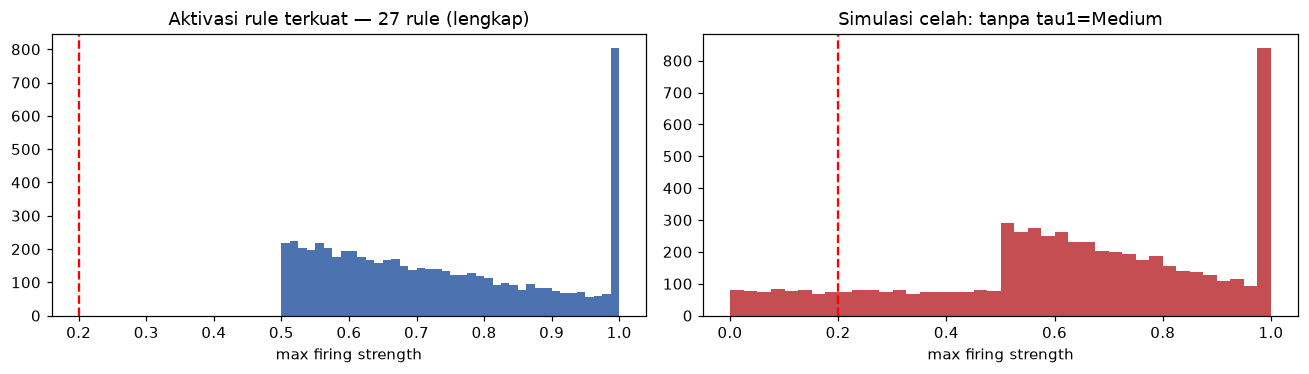

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].hist(maxfire_full, bins=40, color="#4C72B0"); axes[0].axvline(.2, c="r", ls="--")
axes[0].set_title("Aktivasi rule terkuat — 27 rule (lengkap)"); axes[0].set_xlabel("max firing strength")
axes[1].hist(maxfire_gap, bins=40, color="#C44E52"); axes[1].axvline(.2, c="r", ls="--")
axes[1].set_title(f"Simulasi celah: tanpa {FEATS[0]}=Medium"); axes[1].set_xlabel("max firing strength")
plt.tight_layout(); plt.show()

**Hasil Jawaban 12b.**
- **Tiga fitur terpilih: τ1, τ4, τ2.** Ketiganya peringkat teratas di ketiga ukuran (|r| ≈ 0.24, MI ≈ 0.035–0.041, AUC ≈ 0.645, Mann–Whitney p < 10⁻⁷⁶).
  - g2 (peringkat 4) hampir setara kuatnya. Jadi pilihan "3 fitur τ" menang tipis, bukan menang telak.
  - p1–p4 tidak informatif (AUC ≈ 0.50).
  - Catatan kritis: memilih 3 fitur teratas secara individual berarti informasi dari g (elastisitas) tidak terpakai. Ini dibahas lagi di 12d.
- **Rule versi 1 tidak didukung data.** Rentang porsi unstable per konsekuen saling tumpang tindih:
  - "Low" bisa sampai 0.685, padahal rata-rata data 0.638.
  - Rule *Medium–Medium–Medium* diberi konsekuen "Medium" padahal porsi unstable-nya **0.934**, salah satu yang tertinggi (hanya kalah tipis dari *Medium–High–High*, 0.935).
- **Penyebabnya terlihat di plot desil:** pengaruh τ **jenuh** setelah sekitar median (porsi unstable ≈ 0.70–0.77 untuk τ > 4). Bagi stabilitas, Medium dan High sama-sama berbahaya.
- **Rule versi 2** (berdasarkan jumlah input yang Low) memisahkan kelompok jauh lebih rapi dan tanpa tumpang tindih:

  | Konsekuen v2 | Porsi unstable (min–maks) | Rata-rata |
  |---|---|---|
  | Low (≥ 2 input Low) | 0.217 – 0.473 | 0.390 |
  | Medium (1 input Low) | 0.602 – 0.757 | 0.668 |
  | High (0 input Low) | 0.833 – 0.935 | 0.899 |

- **Rule gaps:**
  - Rule base 27 rule lolos kedua pemeriksaan: **0 kombinasi tanpa rule**, dan **aktivasi rule terkuat minimal 0.50** di semua 6.000 sampel latih. Angka 0.50 ini bukan kebetulan. Karena Low + Medium + High = 1 di setiap titik, nilai keanggotaan terbesar tiap input selalu ≥ 0.5, sehingga rule yang cocok selalu aktif minimal 0.5.
  - Detektornya terbukti bekerja: saat 9 rule dengan τ1 = Medium dihapus, langsung terdeteksi **9 kombinasi kosong** dan **608 sampel** (10%) dengan aktivasi < 0.2, terlihat sebagai batang di dekat nol pada histogram kanan. Sampel-sampel ini adalah grid dengan τ1 di sekitar median, yang "tidak dikenali" sistem.

### Jawaban 12c — Implementasi Mamdani FIS dan pemilihan threshold (validation saja)

**Cara kerja Mamdani di `skfuzzy.control`:**
1. **Fuzzification:** nilai τ diubah menjadi derajat Low/Medium/High. Contoh: τ = 6 bisa jadi 0.3 Medium dan 0.7 High.
2. **Inference (min):** setiap rule menghitung firing strength = **min** derajat antecedent-nya (AND). Lalu himpunan output rule itu "dipotong" setinggi firing strength-nya (*clipping*, implikasi min).
3. **Aggregation (max):** potongan dari 27 rule digabung dengan operator **max**, membentuk satu bentuk output gabungan.
4. **Defuzzification (centroid):** dihitung titik berat bentuk gabungan itu, dan hasilnya angka 0–100, yaitu *Instability Risk*.

Konflik antar-rule (misalnya satu rule bilang Low 0.3 dan rule lain bilang High 0.7) diselesaikan otomatis oleh agregasi max dan centroid: hasilnya condong ke arah rule yang aktivasinya lebih kuat.

Setelah risk dihitung, sampel dinyatakan **unstable bila risk ≥ θ**. θ dicari dari 0 sampai 100 (langkah 0.5) dan dipilih yang memaksimalkan **macro-F1 di validation set**. Validation yang sama dipakai untuk memilih rule versi 1 atau versi 2. Test set tidak disentuh sama sekali.

In [15]:
def build_fis(kolom_risk):
    rules = [ctrl.Rule(antecedents[FEATS[0]][r[FEATS[0]]] & antecedents[FEATS[1]][r[FEATS[1]]]
                       & antecedents[FEATS[2]][r[FEATS[2]]], risk[r[kolom_risk]]) for _, r in rule_table.iterrows()]
    return ctrl.ControlSystem(rules)

def fis_risk(fis, X):
    sim = ctrl.ControlSystemSimulation(fis)
    for f in FEATS:
        sim.input[f] = X[f].values            # skfuzzy mendukung input berupa array (vektor)
    sim.compute()
    return np.asarray(sim.output["risk"])

grid = np.arange(0, 100.5, 0.5)
hasil_val = {}
for v in ["risk_v1", "risk_v2"]:
    fis_v = build_fis(v)
    rv = fis_risk(fis_v, X_va)
    f1s = np.array([f1_score(y_va, (rv >= t).astype(int), average="macro") for t in grid])
    hasil_val[v] = {"fis": fis_v, "theta": grid[f1s.argmax()], "f1_val": f1s.max(), "curve": f1s, "r_va": rv}
    print(f"{v}: θ terbaik = {grid[f1s.argmax()]:5.1f} | macro-F1 val = {f1s.max():.4f} | ROC-AUC val = {roc_auc_score(y_va, rv):.4f}")

VERSI = max(hasil_val, key=lambda v: hasil_val[v]["f1_val"])
fis, THETA, r_va = hasil_val[VERSI]["fis"], hasil_val[VERSI]["theta"], hasil_val[VERSI]["r_va"]
r_tr, r_te = fis_risk(fis, X_tr), fis_risk(fis, X_te)
print(f"\n→ Dipakai: {VERSI} dengan θ = {THETA} (dipilih dari validation)")

risk_v1: θ terbaik =  37.5 | macro-F1 val = 0.6749 | ROC-AUC val = 0.7257


risk_v2: θ terbaik =  39.0 | macro-F1 val = 0.6895 | ROC-AUC val = 0.7654



→ Dipakai: risk_v2 dengan θ = 39.0 (dipilih dari validation)


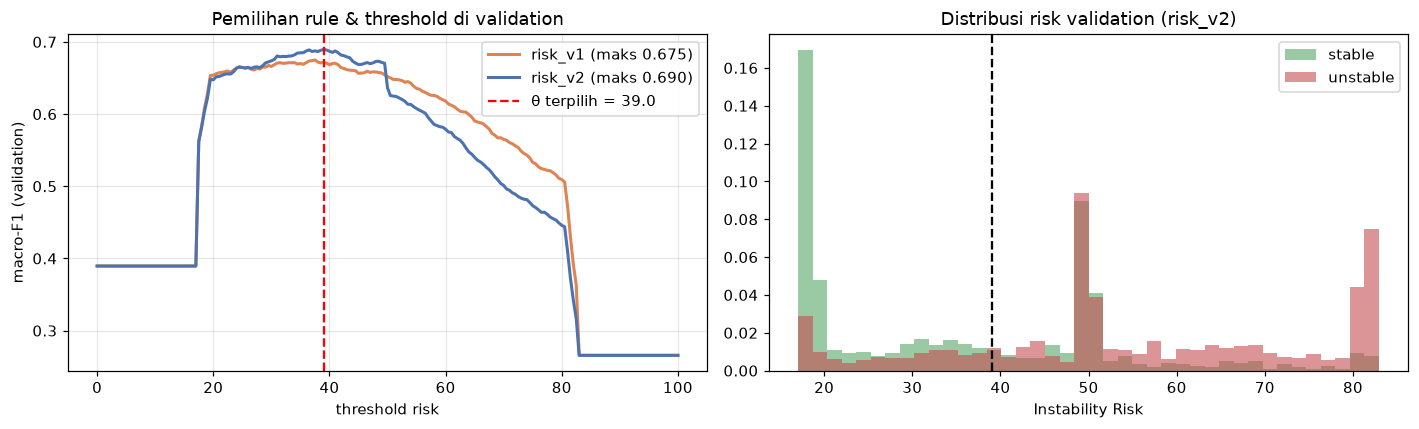

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for v, c in [("risk_v1", "#DD8452"), ("risk_v2", "#4C72B0")]:
    axes[0].plot(grid, hasil_val[v]["curve"], lw=2, color=c, label=f"{v} (maks {hasil_val[v]['f1_val']:.3f})")
axes[0].axvline(THETA, c="r", ls="--", label=f"θ terpilih = {THETA}")
axes[0].set_xlabel("threshold risk"); axes[0].set_ylabel("macro-F1 (validation)"); axes[0].set_title("Pemilihan rule & threshold di validation")
axes[0].legend(); axes[0].grid(alpha=.3)
axes[1].hist(r_va[y_va == 0], bins=40, alpha=.6, density=True, label="stable", color="#55A868")
axes[1].hist(r_va[y_va == 1], bins=40, alpha=.6, density=True, label="unstable", color="#C44E52")
axes[1].axvline(THETA, c="k", ls="--"); axes[1].set_xlabel("Instability Risk"); axes[1].set_title(f"Distribusi risk validation ({VERSI})")
axes[1].legend(); plt.tight_layout(); plt.show()

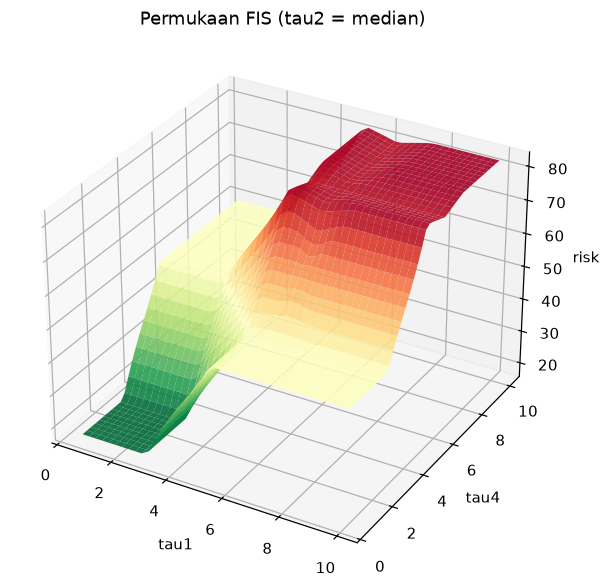

In [17]:
# Surface plot: risk sebagai fungsi dua fitur pertama (fitur ketiga = median)
g1 = np.linspace(mf_par[FEATS[0]]["Low"][0], mf_par[FEATS[0]]["High"][3], 40)
g2 = np.linspace(mf_par[FEATS[1]]["Low"][0], mf_par[FEATS[1]]["High"][3], 40)
G1, G2 = np.meshgrid(g1, g2)
grid_df = pd.DataFrame({FEATS[0]: G1.ravel(), FEATS[1]: G2.ravel(), FEATS[2]: mf_par[FEATS[2]]["Medium"][1]})
Z = fis_risk(fis, grid_df).reshape(G1.shape)
fig = plt.figure(figsize=(8, 5.5)); ax = fig.add_subplot(111, projection="3d")
ax.plot_surface(G1, G2, Z, cmap="RdYlGn_r", edgecolor="none", alpha=.9)
ax.set_xlabel(FEATS[0]); ax.set_ylabel(FEATS[1]); ax.set_zlabel("risk")
ax.set_title(f"Permukaan FIS ({FEATS[2]} = median)"); plt.tight_layout(); plt.show()

## 5. Evaluation

### Hasil FIS di test set

In [18]:
pred_fis = (r_te >= THETA).astype(int)
print(classification_report(y_te, pred_fis, target_names=["stable", "unstable"], digits=3))
cm = confusion_matrix(y_te, pred_fis)
print("Confusion matrix (baris aktual stable/unstable, kolom prediksi):\n", cm)
print(f"ROC-AUC skor risk (test) = {roc_auc_score(y_te, r_te):.4f}")

              precision    recall  f1-score   support

      stable      0.620     0.581     0.600       724
    unstable      0.771     0.798     0.784      1276

    accuracy                          0.720      2000
   macro avg      0.695     0.690     0.692      2000
weighted avg      0.716     0.720     0.717      2000

Confusion matrix (baris aktual stable/unstable, kolom prediksi):
 [[ 421  303]
 [ 258 1018]]
ROC-AUC skor risk (test) = 0.7776


### Jawaban 12d — Perbandingan dengan baseline threshold sederhana

**Baseline:** satu aturan saja, yaitu *"unstable jika `{fitur terbaik}` ≥ t"*. Fitur yang dipakai adalah fitur peringkat pertama, dan t dipilih dengan cara yang **sama persis** dengan FIS (memaksimalkan macro-F1 di validation). Sebagai pembanding tambahan, ditampilkan juga logistic regression pada 3 fitur yang sama untuk mewakili model statistik/*black-box* ringan, supaya terlihat berapa akurasi yang "dikorbankan" demi interpretabilitas.

In [19]:
fb = FEATS[0]
cand = np.quantile(X_tr[fb], np.linspace(0.01, 0.99, 197))
f1_b = [f1_score(y_va, (X_va[fb].values >= t).astype(int), average="macro") for t in cand]
T_BASE = cand[int(np.argmax(f1_b))]
pred_base = (X_te[fb].values >= T_BASE).astype(int)

sc = StandardScaler().fit(X_tr[FEATS])
lr = LogisticRegression().fit(sc.transform(X_tr[FEATS]), y_tr)
p_va_lr, p_te_lr = lr.predict_proba(sc.transform(X_va[FEATS]))[:, 1], lr.predict_proba(sc.transform(X_te[FEATS]))[:, 1]
t_lr = grid[np.argmax([f1_score(y_va, (p_va_lr * 100 >= t).astype(int), average="macro") for t in grid])] / 100
pred_lr = (p_te_lr >= t_lr).astype(int)

def ringkas(nama, pred, skor, n_aturan):
    return {"model": nama, "jumlah aturan / parameter": n_aturan, "accuracy": accuracy_score(y_te, pred),
            "balanced_acc": balanced_accuracy_score(y_te, pred), "macro_F1": f1_score(y_te, pred, average="macro"),
            "recall_unstable": (pred[y_te == 1] == 1).mean(), "specificity": (pred[y_te == 0] == 0).mean(),
            "ROC_AUC": roc_auc_score(y_te, skor)}

LAIN = "risk_v1" if VERSI == "risk_v2" else "risk_v2"
r_te_lain = fis_risk(hasil_val[LAIN]["fis"], X_te)
print(f"Baseline: unstable jika {fb} ≥ {T_BASE:.3f}")
cmp = pd.DataFrame([ringkas(f"Baseline: {fb} ≥ {T_BASE:.2f}", pred_base, X_te[fb].values, "1 aturan"),
                    ringkas(f"Mamdani FIS ({VERSI}, θ={THETA})", pred_fis, r_te, "27 rule + 12 MF"),
                    ringkas(f"FIS {LAIN} (tidak terpilih, info saja)", (r_te_lain >= hasil_val[LAIN]["theta"]).astype(int),
                            r_te_lain, "27 rule + 12 MF"),
                    ringkas("Logistic regression (3 input)", pred_lr, p_te_lr, "4 koefisien")])
cmp.round(4)

Baseline: unstable jika tau1 ≥ 3.157


,model,jumlah aturan / parameter,accuracy,balanced_acc,macro_F1,recall_unstable,specificity,ROC_AUC
0,Baseline: tau1 ≥ 3.16,1 aturan,0.6760,0.6227,0.6262,0.8158,0.4296,0.6257
1,"Mamdani FIS (risk_v2, θ=39.0)",27 rule + 12 MF,0.7195,0.6896,0.6921,0.7978,0.5815,0.7776
2,"FIS risk_v1 (tidak terpilih, info saja)",27 rule + 12 MF,0.7020,0.6813,0.6799,0.7563,0.6064,0.7454
3,Logistic regression (3 input),4 koefisien,0.6930,0.6811,0.6757,0.7241,0.6381,0.7535


**Contoh penjelasan FIS untuk satu sampel test.** Inilah nilai tambah utama FIS: setiap keputusan bisa ditelusuri ke rule yang aktif.

In [20]:
def jelaskan(i):
    xi = X_te.iloc[[i]]
    fr = firing(xi, rule_table)[0]
    top = np.argsort(fr)[::-1][:3]
    print(f"Sampel test #{i}: " + ", ".join(f"{f}={xi[f].values[0]:.2f}" for f in FEATS)
          + f" → risk = {r_te[i]:.1f} (θ={THETA}) → prediksi {'UNSTABLE' if r_te[i] >= THETA else 'stable'}"
          f", aktual {'UNSTABLE' if y_te[i] else 'stable'}")
    for k in top:
        r = rule_table.iloc[k]
        print(f"   aktivasi {fr[k]:.2f}: IF " + " AND ".join(f"{f} is {r[f]}" for f in FEATS) + f" THEN risk is {r[VERSI]}")

jelaskan(int(np.argmax(r_te)))
jelaskan(int(np.argmin(r_te)))
salah = np.where((pred_fis == 0) & (y_te == 1))[0]
jelaskan(int(salah[0]))

Sampel test #62: tau1=9.75, tau4=9.71, tau2=7.65 → risk = 82.9 (θ=39.0) → prediksi UNSTABLE, aktual UNSTABLE
   aktivasi 1.00: IF tau1 is High AND tau4 is High AND tau2 is High THEN risk is High
   aktivasi 0.00: IF tau1 is Medium AND tau4 is Medium AND tau2 is Low THEN risk is Medium
   aktivasi 0.00: IF tau1 is Low AND tau4 is Low AND tau2 is Medium THEN risk is Low
Sampel test #9: tau1=1.36, tau4=1.45, tau2=0.62 → risk = 17.1 (θ=39.0) → prediksi stable, aktual stable
   aktivasi 1.00: IF tau1 is Low AND tau4 is Low AND tau2 is Low THEN risk is Low
   aktivasi 0.00: IF tau1 is Medium AND tau4 is Medium AND tau2 is Low THEN risk is Medium
   aktivasi 0.00: IF tau1 is Low AND tau4 is Low AND tau2 is Medium THEN risk is Low
Sampel test #8: tau1=9.93, tau4=4.36, tau2=0.86 → risk = 38.6 (θ=39.0) → prediksi stable, aktual UNSTABLE
   aktivasi 0.64: IF tau1 is High AND tau4 is Medium AND tau2 is Low THEN risk is Medium
   aktivasi 0.36: IF tau1 is High AND tau4 is Low AND tau2 is Low THEN r

**Hasil Jawaban 12c–12d.**

**Pemilihan di validation.** Rule versi 2 menang (macro-F1 val 0.690 vs 0.675; ROC-AUC val 0.765 vs 0.726), dengan θ = **39.0**. Angka ini lalu diuji **sekali** di test set:

| Model | Aturan | Accuracy | Balanced acc | Macro-F1 | Recall unstable | Specificity | ROC-AUC |
|---|---|---|---|---|---|---|---|
| Baseline τ1 ≥ 3.16 | 1 | 0.676 | 0.623 | 0.626 | 0.816 | 0.430 | 0.626 |
| **Mamdani FIS v2** | 27 rule | **0.720** | **0.690** | **0.692** | 0.798 | 0.582 | **0.778** |
| FIS v1 (info) | 27 rule | 0.702 | 0.681 | 0.680 | 0.756 | 0.606 | 0.745 |
| Logistic regression | 4 koef. | 0.693 | 0.681 | 0.676 | 0.724 | 0.638 | 0.754 |

**Analisis performa.**
- **Baseline** hanya punya satu "saklar". Supaya recall unstable tinggi (0.82), ia terpaksa menuduh sebagian besar grid stabil sebagai unstable (specificity hanya 0.43). Satu fitur tidak cukup.
- **FIS v2 unggul atas baseline** di semua metrik gabungan: macro-F1 +0.066, ROC-AUC +0.15. Menggabungkan tiga waktu reaksi lewat rule memberi gambaran yang lebih lengkap.
- Menariknya, **FIS v2 juga sedikit mengungguli logistic regression** (AUC 0.778 vs 0.754). Logistic regression menganggap efek τ lurus ("makin besar makin berbahaya"), padahal datanya jenuh. Rule fuzzy versi 2 menangkap pola jenuh itu secara eksplisit. Ini contoh di mana pengetahuan yang dituangkan dalam rule justru menambah akurasi.
- **Keterbatasan:**
  - Skor risk hanya punya sedikit "anak tangga". Banyak sampel bernilai persis 17.1, 50.0, atau 82.9: ketika hanya satu rule aktif penuh, centroid himpunan outputnya selalu di titik yang sama (lihat juga permukaan FIS yang berundak).
  - Plafon akurasi ~0.72 karena FIS hanya melihat 3 dari 12 fitur. Elastisitas g yang juga informatif tidak dipakai.
  - Contoh sampel #8 (τ1 = 9.93, τ4 = 4.36, τ2 = 0.86) memperlihatkan efek ini. Risk-nya 38.6, tepat di bawah θ = 39, karena satu peserta bereaksi cepat (τ2 Low) sehingga rule "Medium" dan "Low" aktif. Padahal grid itu unstable, kemungkinan karena faktor g yang tidak dilihat FIS.

**Analisis interpretabilitas.**

| Aspek | Baseline | Mamdani FIS | Logistic regression |
|---|---|---|---|
| Bentuk keputusan | satu ambang | 27 kalimat IF–THEN | bobot × fitur → sigmoid |
| Bisa dijelaskan ke operator? | ya, tapi terlalu kasar | **ya, per sampel ditunjukkan rule yang aktif** | perlu paham log-odds |
| Bisa diedit pakar tanpa melatih ulang? | ya | **ya, cukup ubah satu rule** | tidak |
| Output | ya/tidak | **skor bertingkat 0–100** | probabilitas |

**Kapan FIS lebih layak walaupun akurasinya sedikit lebih rendah?**
1. **Keputusan harus bisa diaudit**, misalnya operator grid harus menjelaskan kenapa beban dilepas. FIS bisa menjawab *"karena τ1, τ4, dan τ2 semuanya High, sehingga rule 27 aktif 100%"*.
2. **Data sedikit tetapi ada pengetahuan pakar.** Rule bisa ditulis dari teori kontrol walau data belum banyak, lalu dikoreksi data seperti versi 1 → versi 2 di sini.
3. **Butuh peringatan bertingkat**, bukan sekadar stabil/tidak. Skor 0–100 bisa dipetakan ke level siaga hijau/kuning/merah.
4. **Keamanan dan kepercayaan.** Perilaku FIS bisa diperiksa di seluruh ruang input lewat permukaan dan cek celah rule, sehingga tidak ada "kejutan" di input yang jarang muncul. Model *black-box* lebih sulit dijamin seperti ini.

Kalau yang dikejar murni akurasi, model non-linear dengan **12 fitur** (misalnya *gradient boosting* atau MLP) jauh lebih tepat. Tetapi untuk kebutuhan "indikator risiko yang bisa dijelaskan", FIS 3 input ini sudah memenuhi target dan bahkan menyamai model statistik sederhana.

## 6. Interpretasi Hasil

### 6.1 Prediksi vs aktual pada 20 sampel test

In [21]:
tab = X_te[FEATS].iloc[:20].round(3).copy()
tab["risk_FIS"] = r_te[:20].round(1)
tab["prediksi"] = np.where(pred_fis[:20] == 1, "unstable", "stable")
tab["aktual"] = np.where(y_te[:20] == 1, "unstable", "stable")
tab["benar?"] = tab["prediksi"] == tab["aktual"]
tab

,tau1,tau4,tau2,risk_FIS,prediksi,aktual,benar?
746,9.136,4.564,5.733,72.7,unstable,stable,False
25,6.192,5.164,2.534,49.4,unstable,stable,False
3011,4.611,1.877,4.572,40.5,unstable,unstable,True
1364,0.973,5.874,5.574,50.0,unstable,unstable,True
4009,3.010,8.533,9.027,52.2,unstable,unstable,True
2941,7.400,4.774,2.403,43.9,unstable,unstable,True
2154,4.717,4.867,6.515,64.7,unstable,unstable,True
8650,8.031,5.239,0.595,50.0,unstable,stable,False
9989,9.929,4.355,0.864,38.6,stable,unstable,False
2643,1.356,1.448,0.617,17.1,stable,stable,True


**Interpretasi uji akhir.**
- Dari 20 sampel test, **14 ditebak benar** (4 false alarm, 2 unstable yang terlewat).
- Grid dengan ketiga τ kecil (misalnya baris 2643: 1.36 / 1.45 / 0.62) mendapat risk **17.1** dan memang stabil.
- Tiga dari empat false alarm punya risk ≈ 50 (satu input Low). Kelompok ini memang campuran (porsi unstable ~0.67), sehingga FIS hanya bisa memberi risiko "sedang". Ini wajar untuk zona abu-abu, bukan kesalahan rule.

### 6.2 Pengecekan kriteria kesuksesan

| Kriteria | Target | Hasil | Status |
|---|---|---|---|
| Rule base lengkap | 0 kombinasi kosong dan 0 sampel aktivasi < 0.2 | 0 dan 0 (aktivasi min 0.50) | ✅ |
| FIS > baseline | macro-F1 test lebih tinggi | 0.692 vs 0.626 | ✅ |
| Ranking skor risk | ROC-AUC ≥ 0.70 | 0.778 | ✅ |

### 6.3 Kesimpulan
1. Tiga fitur paling informatif menurut statistik data latih adalah **τ1, τ4, τ2** (waktu reaksi peserta grid). Membership Low/Medium/High dibangun dari kuartil data latih dan membentuk *fuzzy partition* yang menutup seluruh universe.
2. Rule base 27 rule menjamin coverage penuh. Dua metode deteksi celah (struktural dan aktivasi empiris) terbukti bekerja lewat simulasi penghapusan rule.
3. Validasi rule dengan data latih mengungkap bahwa asumsi awal "makin lama reaksi makin berbahaya secara lurus" **salah**: efek τ jenuh. Rule revisi berdasarkan "jumlah peserta yang bereaksi cepat" lebih akurat dan tetap mudah dibaca.
4. Dengan θ = 39 (dipilih dari validation), FIS mencapai accuracy 0.720, macro-F1 0.692, dan ROC-AUC 0.778 di test. FIS jelas mengungguli baseline satu ambang dan sedikit mengungguli logistic regression.
5. Keterbatasan: skor risk berundak (sering tepat 17.1 / 50 / 82.9) dan hanya memakai 3 dari 12 fitur. Pengembangan: tambahkan input g (elastisitas) lewat hierarchical FIS agar jumlah rule tidak meledak, atau setel parameter membership dari data latih (misalnya dengan ANFIS).